## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

## *Phase 1:

Declaration Signature: Graham Evans

Date Completed: 10/20

In [10]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

**Q1.**

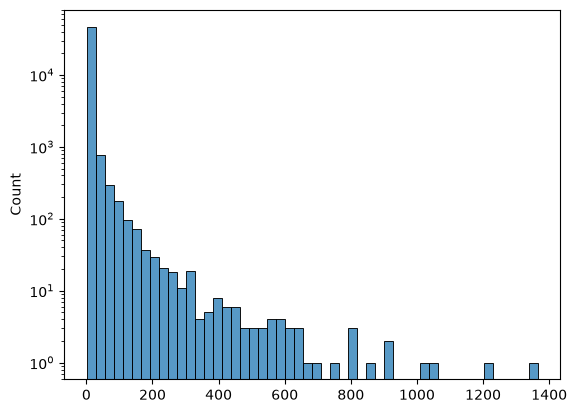

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot([token_count[token] for token in token_count], bins=50)
plt.yscale('log')

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

#### Answer:
The histogram is skewed right, so as the frequency of occurance increases, the number of tokens decreases. The small amount of tokens at the rightward tail of the histogram have a very high frequency while the majority of tokens have a relatively low frequency.

**Q2.** 

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler



data = pd.read_parquet('data/Phishing_clean.parquet')
len(data)

#1.
X = data.drop(columns=["Email Type"])
Y = data["Email Type"]
classification_X_raw = data[["Email Type"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=50,
    stratify=Y,
)

#2.
model = LinearRegression()
model.fit(X_train, y_train)

print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

#3.
coefs = pd.Series(model.coef_, index=X_train.columns)
top = coefs[coefs.abs().nlargest(5).index]
print(top)




0.7687749746991981
0.6540676060978555
helvetica,           0.964489
background-image:   -0.816539
localized            0.753812
thermal              0.741281
none;               -0.623966
dtype: float64


**Q3.** 

[0.09, 0.07, 0.07, 0.06, 0.06, 0.06, 0.05, 0.05, 0.05, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.03, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.0

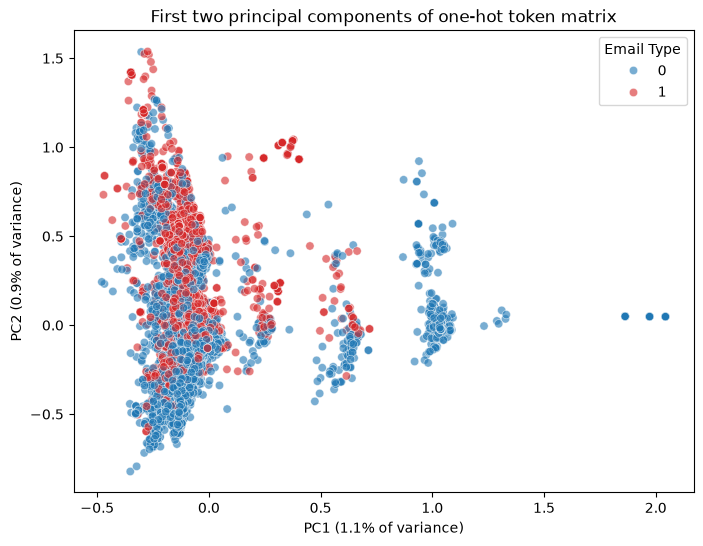

please    -0.109197
would     -0.089941
like      -0.089732
get       -0.067595
message   -0.049269
enron     -0.046540
email     -0.045669
call      -0.043308
know      -0.043171
dear      -0.041413
Name: PC1, dtype: float64
failure      0.062330
schedule     0.062773
required     0.063315
schedules    0.194364
ancillary    0.194725
hourahead    0.255696
hour         0.260594
start        0.287437
url:         0.367390
date         0.674016
Name: PC1, dtype: float64
please       -0.200660
message      -0.149039
call         -0.133802
attached     -0.133462
enron        -0.116282
conference   -0.100374
original     -0.094455
papers       -0.086622
university   -0.082093
see          -0.055564
Name: PC2, dtype: float64
online       0.082438
available    0.082556
one          0.118190
software     0.127440
offer        0.136154
hello        0.144890
get          0.316850
would        0.318753
like         0.414520
new          0.451125
Name: PC2, dtype: float64


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

X = data.drop(columns=["Email Type"])
y = data["Email Type"]

correlations = X.corr()
Z = X - X.mean()
C = (Z.T @ Z) / (len(Z) - 1)

eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
print(eigenvalues.round(2).tolist())

L = 2
P = eigenvectors[:, :L]
X_pca = Z @ P
explained_ratio = eigenvalues / eigenvalues.sum()

print("Dimensions:", X.shape, "→", X_pca.shape)
print("Variance retained:", round(100 * explained_ratio[:L].sum(), 1), "%")

pca = PCA(n_components=L).fit(X)
X_pca_sklearn = pca.transform(X)
print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca.explained_variance_ratio_.round(3))
print("Manual: ", explained_ratio[:L].round(3))

pca_df = pd.DataFrame(X_pca.values, columns=["PC1", "PC2"])
pca_df["Email Type"] = y.values

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2",
    hue="Email Type", alpha=0.6, palette={0: "tab:blue", 1: "tab:red"},
)
plt.title("First two principal components of one-hot token matrix")
plt.xlabel(f"PC1 ({explained_ratio[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({explained_ratio[1]:.1%} of variance)")
plt.show()

loadings = pd.DataFrame(P, index=X.columns, columns=["PC1", "PC2"])
print(loadings["PC1"].sort_values().head(10))   # most negative
print(loadings["PC1"].sort_values().tail(10))   # most positive
print(loadings["PC2"].sort_values().head(10))
print(loadings["PC2"].sort_values().tail(10))


#### Observations:

There appears to be clumps of data points, segmented by PC1. The main clump is between values of -0.5 and for PC1. Additionally, the email type 0 has higher values for PC1 whereas the email type 1 has lower values generally.

**Q4.**

In [14]:

k = 2610
pca = PCA(n_components=k)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)
pcr = LinearRegression().fit(Z_train, y_train)

print(pcr.score(Z_train, y_train))
print(pcr.score(Z_test, y_test))

0.7679184562778704
0.656088832799794


#### Observations:
The R^2 values on the training and test sets are very similar to those of the linear regression from earlier which makes sense given the sample size relative to the full size.

**Q5.**

#### Answer:
Using principle components instead of original data is more beneficial because it reduces any overfitting of the data since there is so many different pieces. Additionally, principle components are unrelated which is beneficial in that many tokens/words can be correlated to each other in specific contexts.

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]